In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier as KNC
from sklearn.svm import SVC 
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("emails.csv")
print(df.head())
df.shape

  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]


(5172, 3002)

In [3]:
X = df.drop(["Email No.","Prediction"],axis = 1)
y = df["Prediction"]
print(X.shape,"\n",y.shape)

(5172, 3000) 
 (5172,)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size =  0.18, random_state = 60, stratify = y)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(4241, 3000) (4241,) (931, 3000) (931,)


In [5]:
sc = StandardScaler()

In [6]:
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [7]:
knn = KNC(n_neighbors = 5)

In [8]:
knn.fit(X_train,y_train)
y_knn_pred = knn.predict(X_test)

In [9]:
svc = SVC(kernel = "linear")

In [10]:
svc.fit(X_train, y_train)
y_svc_pred = svc.predict(X_test)

In [11]:
svc_acc = accuracy_score(y_test, y_knn_pred)
knn_acc = accuracy_score(y_test, y_svc_pred)

In [12]:
print("SVM Accuracy: ",round(svc_acc*100, 2))
print("KNN Accuracy: ",round(knn_acc*100, 2))

SVM Accuracy:  82.38
KNN Accuracy:  95.06


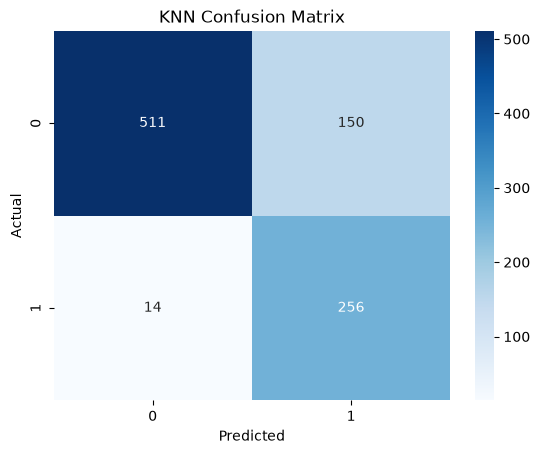

In [13]:
sns.heatmap(confusion_matrix(y_test, y_knn_pred),
            annot=True, fmt='d', cmap='Blues')
plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

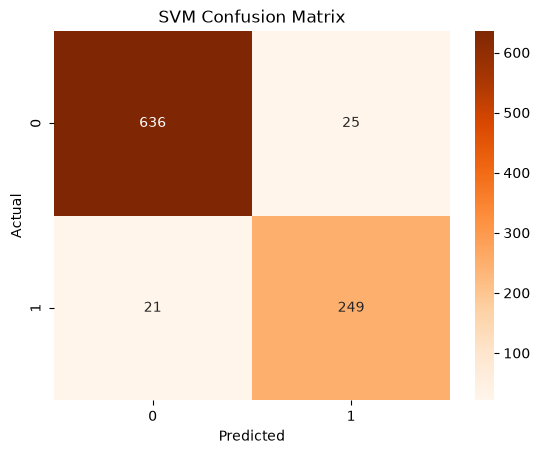

In [14]:
sns.heatmap(confusion_matrix(y_test, y_svc_pred),
            annot=True, fmt='d', cmap='Oranges')
plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()